# Customer Campaign Response Prediction
Binary classification on the Customer Personality Analysis dataset (target: `Response`).
Models: Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest.

**Before running:** `marketing_campaign.csv` must be in the same folder as this notebook.

In [25]:
!pip install numpy scikit-learn

## 1. Imports and setup

In [28]:
import os, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("model", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 2. Load data and examine it
The file has an `.xls`/`.csv` name but is tab-separated text, so `sep='\t'` is used.

In [31]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
print("Raw shape:", df.shape)
df.head()

Raw shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [33]:
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

Missing values:
Income    24
dtype: int64


### Class distribution (imbalance check)

Response
0    1906
1     334
Name: count, dtype: int64
Response
0    0.8509
1    0.1491
Name: proportion, dtype: float64


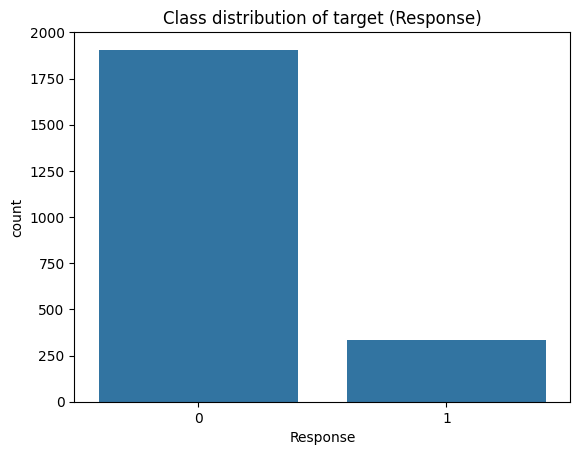

In [36]:
print(df["Response"].value_counts())
print(df["Response"].value_counts(normalize=True).round(4))
sns.countplot(x="Response", data=df)
plt.title("Class distribution of target (Response)")
plt.savefig("results/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Cleaning and feature engineering

In [39]:
# constant columns carry no information; ID is only an identifier
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])
dups = df.drop(columns=["ID"]).duplicated().sum()
print("Duplicate customers (ignoring ID):", dups)
df = df.drop(columns=["ID"]).drop_duplicates().reset_index(drop=True)

# engineered features (data was collected around 2014)
df["Age"] = 2014 - df["Year_Birth"]
df["Customer_Tenure_Days"] = (pd.Timestamp("2014-12-31") -
                              pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")).dt.days
df = df.drop(columns=["Year_Birth", "Dt_Customer"])

# remove impossible ages and tidy marital status labels
df = df[df["Age"] < 100]
df["Marital_Status"] = df["Marital_Status"].replace(
    {"Alone": "Single", "Absurd": "Other", "YOLO": "Other"})

X = df.drop(columns="Response")
y = df["Response"]
print("Shape after cleaning:", X.shape)

cat_cols = ["Education", "Marital_Status"]
num_cols = [c for c in X.select_dtypes(include="number").columns if c not in cat_cols]

Duplicate customers (ignoring ID): 182
Shape after cleaning: (2055, 25)


## 4. Train-test split (80:20, stratified, fixed seed)

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train positive rate:", round(y_train.mean(), 4), "| Test:", round(y_test.mean(), 4))

# save the test data for the GitHub repo
pd.concat([X_test, y_test], axis=1).to_csv("test_data.csv", index=False)

Train: (1644, 25) Test: (411, 25)
Train positive rate: 0.1521 | Test: 0.1533


## 5. Preprocessing (fitted on training data only, inside a Pipeline)

In [45]:
def make_preprocessor(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
    ])

# (needs_scaling, model) - scaling matters for LR / kNN / NB, not for trees
models = {
    "Logistic Regression": (True,  LogisticRegression(max_iter=1000, random_state=SEED)),
    "Decision Tree":       (False, DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=SEED)),
    "kNN":                 (True,  KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes":         (True,  GaussianNB()),
    "Random Forest (Ensemble)": (False, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
}

## 6. Train and evaluate all models

In [48]:
rows, cms = [], {}
for name, (scale, clf) in models.items():
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("clf", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "AUC":       roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "MCC":       matthews_corrcoef(y_test, pred),
    })
    cms[name] = confusion_matrix(y_test, pred)
    fname = name.split(" (")[0].lower().replace(" ", "_") + ".pkl"
    joblib.dump(pipe, os.path.join("model", fname))

res = pd.DataFrame(rows).set_index("ML Model Name").round(4)
res.to_csv("results/metrics.csv")
res

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8783,0.8736,0.6383,0.4762,0.5455,0.4838
Decision Tree,0.8540,0.7483,0.5429,0.3016,0.3878,0.3299
kNN,0.8613,0.7938,0.6071,0.2698,0.3736,0.3406
Naive Bayes,0.8321,0.8071,0.4643,0.6190,0.5306,0.4375
Random Forest (Ensemble),0.8613,0.8542,0.6071,0.2698,0.3736,0.3406


## 7. Visualisations

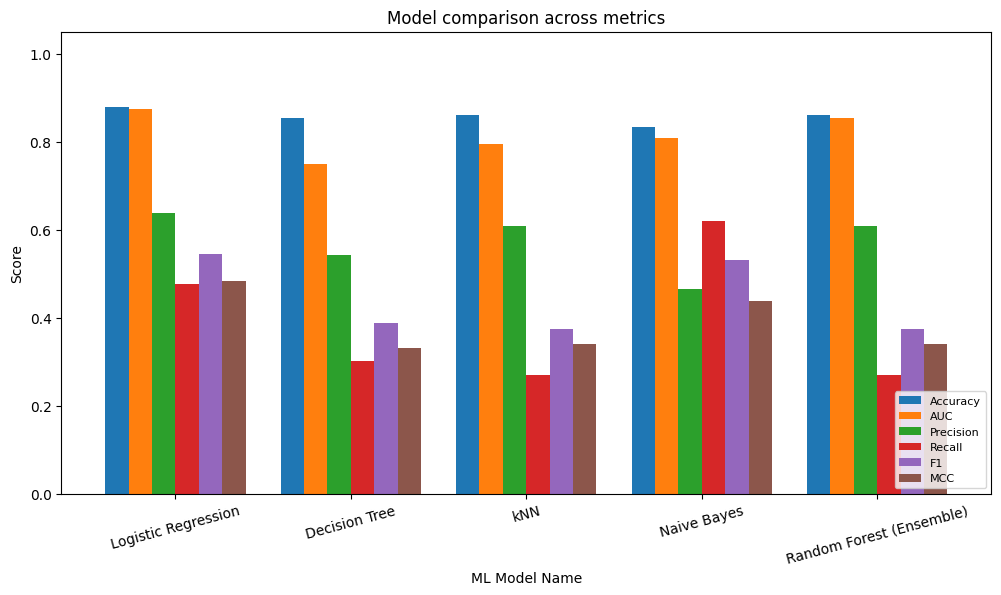

In [51]:
ax = res.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Model comparison across metrics"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
plt.xticks(rotation=15); plt.legend(loc="lower right", fontsize=8)
plt.savefig("results/metrics_by_model.png", dpi=150, bbox_inches="tight")
plt.show()

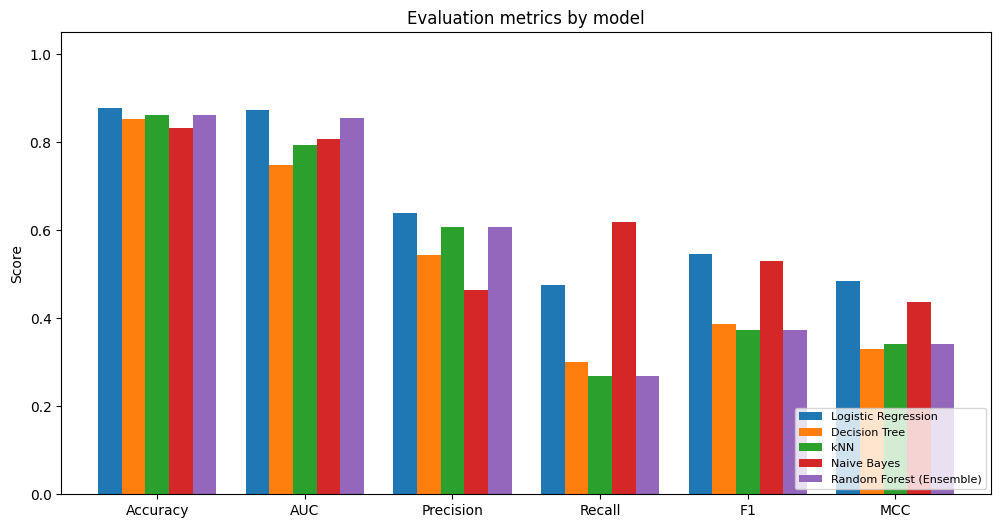

In [53]:
ax = res.T.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("Evaluation metrics by model"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
plt.xticks(rotation=0); plt.legend(loc="lower right", fontsize=8)
plt.savefig("results/metrics_by_metric.png", dpi=150, bbox_inches="tight")
plt.show()

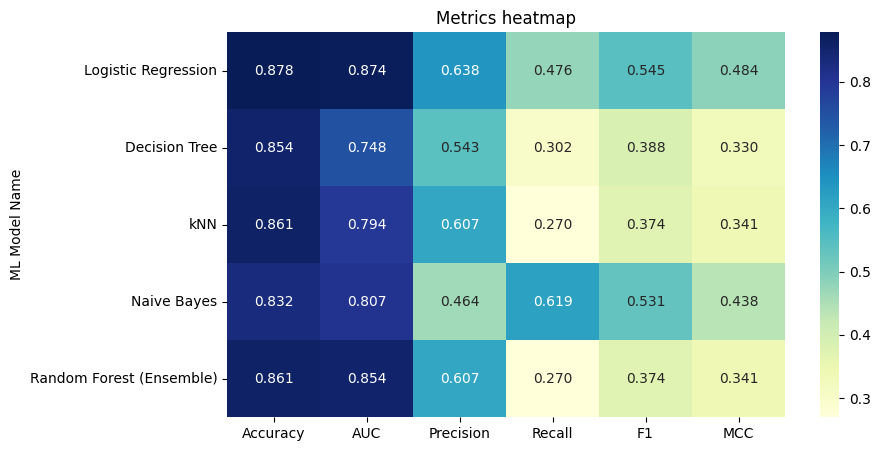

In [55]:
plt.figure(figsize=(9, 5))
sns.heatmap(res, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Metrics heatmap")
plt.savefig("results/metrics_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

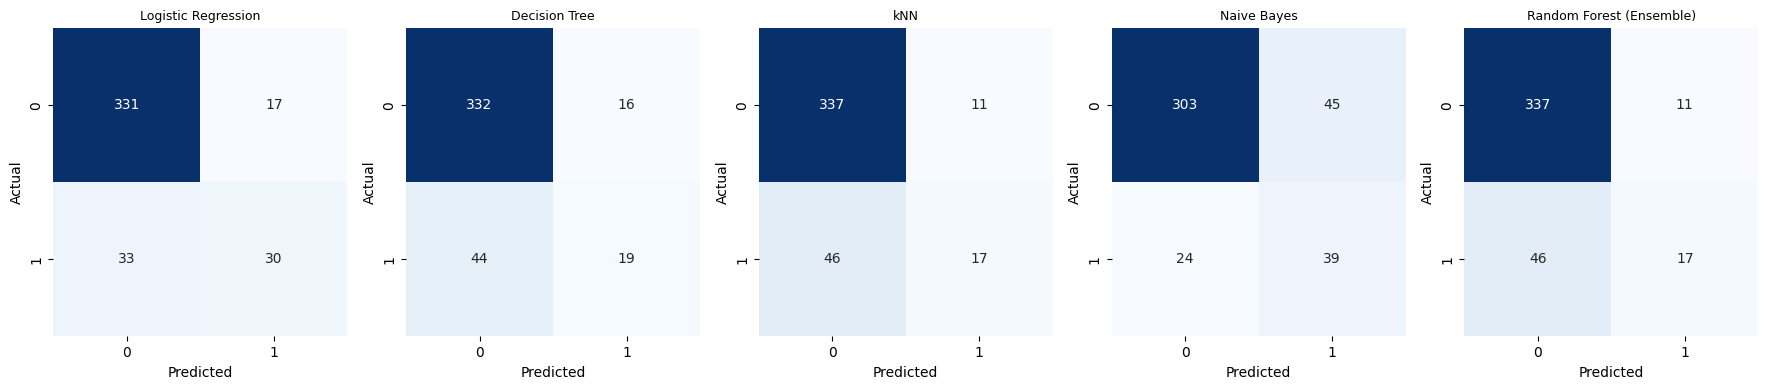

In [57]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for a, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a)
    a.set_title(n, fontsize=9); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.savefig("results/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()